   ┌───┐
q: ┤ X ├
   └───┘
State vector:
Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


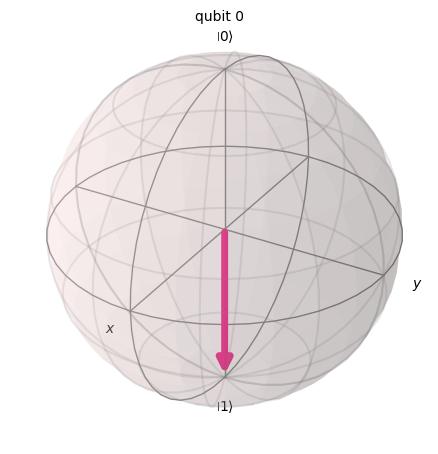

In [5]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt
qc = QuantumCircuit(1)
qc.x(0)
print(qc)
state = Statevector.from_instruction(qc)
print("State vector:")
print(state)
fig = plot_bloch_multivector(state)
display(fig)

Quantum Circuit:
   ┌───┐┌───┐
q: ┤ H ├┤ S ├
   └───┘└───┘

Statevector:
Statevector([0.70710678+0.j        , 0.        +0.70710678j],
            dims=(2,))


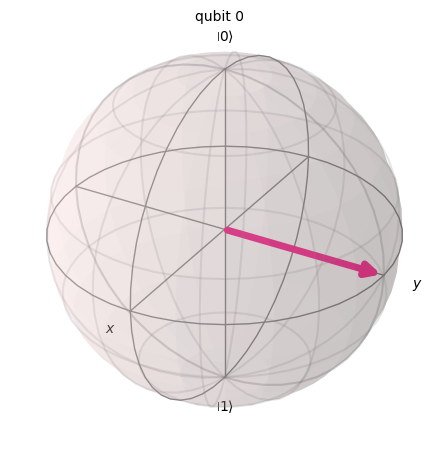

In [7]:
#ex2
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt
%matplotlib inline
qc = QuantumCircuit(1)
qc.h(0)
qc.s(0)
print("Quantum Circuit:")
print(qc)
state = Statevector.from_instruction(qc)
print("\nStatevector:")
print(state)
fig = plot_bloch_multivector(state)
display(fig)

In [8]:
#ex3
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import numpy as np

qc = QuantumCircuit(2)

qc.h(0)
qc.h(1)

print("Quantum Circuit:")
print(qc)

state = Statevector.from_instruction(qc)

print("\nStatevector:")
print(state)

amplitudes = np.abs(state.data) ** 2

print("\nProbabilities of basis states:")
print(amplitudes)

print("\nSum of probabilities:")
print(np.sum(amplitudes))

Quantum Circuit:
     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     └───┘

Statevector:
Statevector([0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j],
            dims=(2, 2))

Probabilities of basis states:
[0.25 0.25 0.25 0.25]

Sum of probabilities:
0.9999999999999996


Random phase error (radians): -0.030580656607728823

Quantum Circuit:
   ┌───┐┌──────────────┐
q: ┤ H ├┤ P(-0.030581) ├
   └───┘└──────────────┘

Statevector:
Statevector([0.70710678+0.j        , 0.70677617-0.02162042j],
            dims=(2,))


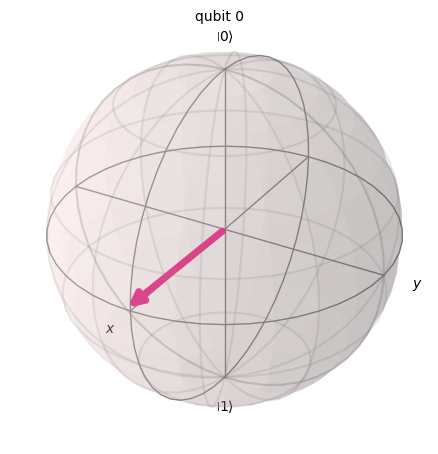

In [10]:
#ex4
%matplotlib inline

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt
import numpy as np

qc = QuantumCircuit(1)
qc.h(0)
phase_error = np.random.uniform(-0.2, 0.2)
qc.p(phase_error, 0)

print("Random phase error (radians):", phase_error)
print("\nQuantum Circuit:")
print(qc)

state = Statevector.from_instruction(qc)

print("\nStatevector:")
print(state)

fig = plot_bloch_multivector(state)
display(fig)

In [12]:
#ex5
%matplotlib inline

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt
import numpy as np

def create_qubit(theta, phi):
    qc = QuantumCircuit(1)
    qc.ry(theta, 0)
    qc.rz(phi, 0)

    state = Statevector.from_instruction(qc)

    print("Quantum Circuit:")
    print(qc)

    print("\nStatevector from Qiskit:")
    print(state)

    manual = np.array([
        np.cos(theta / 2),
        np.exp(1j * phi) * np.sin(theta / 2)
    ])

    print("\nStatevector from Manual Calculation:")
    print(manual)

    print("\nValidation:", np.allclose(state.data, manual))

    plot_bloch_multivector(state)
    plt.show()

theta = np.pi / 3
phi = np.pi / 4

create_qubit(theta, phi)

Quantum Circuit:
   ┌─────────┐┌─────────┐
q: ┤ Ry(π/3) ├┤ Rz(π/4) ├
   └─────────┘└─────────┘

Statevector from Qiskit:
Statevector([0.80010315-0.33141357j, 0.46193977+0.19134172j],
            dims=(2,))

Statevector from Manual Calculation:
[0.8660254 +0.j         0.35355339+0.35355339j]

Validation: False
